# Explainable SUMO surrogates — validation-first study

This notebook reproduces every result, table and figure of the article, in order:

| § | Analysis | Question |
|---|---|---|
| 3 | Partitioned designs (512 Sobol / 200 / 200×5 seeds) | Independent evaluation data |
| 4 | Development CV and frozen surrogates (incl. Gaussian process) | Model fitting |
| 5 | Independent test + noise ceiling | Accuracy on new settings |
| 6 | Train → calibrate → test predictive intervals | Interval coverage |
| 7 | Repeated-seed replication | Seed noise |
| 8 | Interventions re-simulated with matched seeds + random control | Achieved reductions |
| 9 | Inverse calibration on excluded targets, two objectives | Identifiability |
| 10 | Headway × departure-variation factorial | Transit mechanism |
| 11 | Direct-SUMO Sobol indices (simulator ground truth) | Simulator sensitivity |
| 12 | Refit stability of Sobol/SHAP/ALE; DML projection | Explanation stability |
| 13 | Learning curve vs. noise floor | Sample size |
| 14 | Teleport rule, rerouting, 8×8 transfer and adaptation | Simulator and network robustness |
| 15–16 | Figures and frozen export | Reproducibility |

Every stage is **resumable**: SUMO runs are cached by a hash of (simulator fingerprint,
parameters, seed); completed stages are skipped. The analysis protocol fixed before the full
run is in `docs/ANALYSIS_PROTOCOL.md`.

## 1. Environment
Runs locally (Eclipse SUMO 1.28 on PATH) or on Google Colab (set `ON_COLAB`).

In [1]:
import os, sys, subprocess
from pathlib import Path
ON_COLAB = "google.colab" in sys.modules
if ON_COLAB:
    subprocess.run("pip -q install eclipse-sumo==1.28.0 -r requirements.txt", shell=True, check=True)
    import sumo; os.environ["PATH"] = str(Path(sumo.SUMO_HOME) / "bin") + os.pathsep + os.environ["PATH"]
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
print(subprocess.check_output(["sumo", "--version"], text=True).splitlines()[0])

Eclipse SUMO sumo 1.28.0


## 2. Study configuration
`PROFILE = "smoke"` checks the whole pipeline in ~3 minutes; `"full"` is the paper (≈10,000 SUMO runs; ≈90 min on 8 cores).

/Users/mahbubhassan/Downloads/suggortate sumo_xai project/sumo-surrogate-xai/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


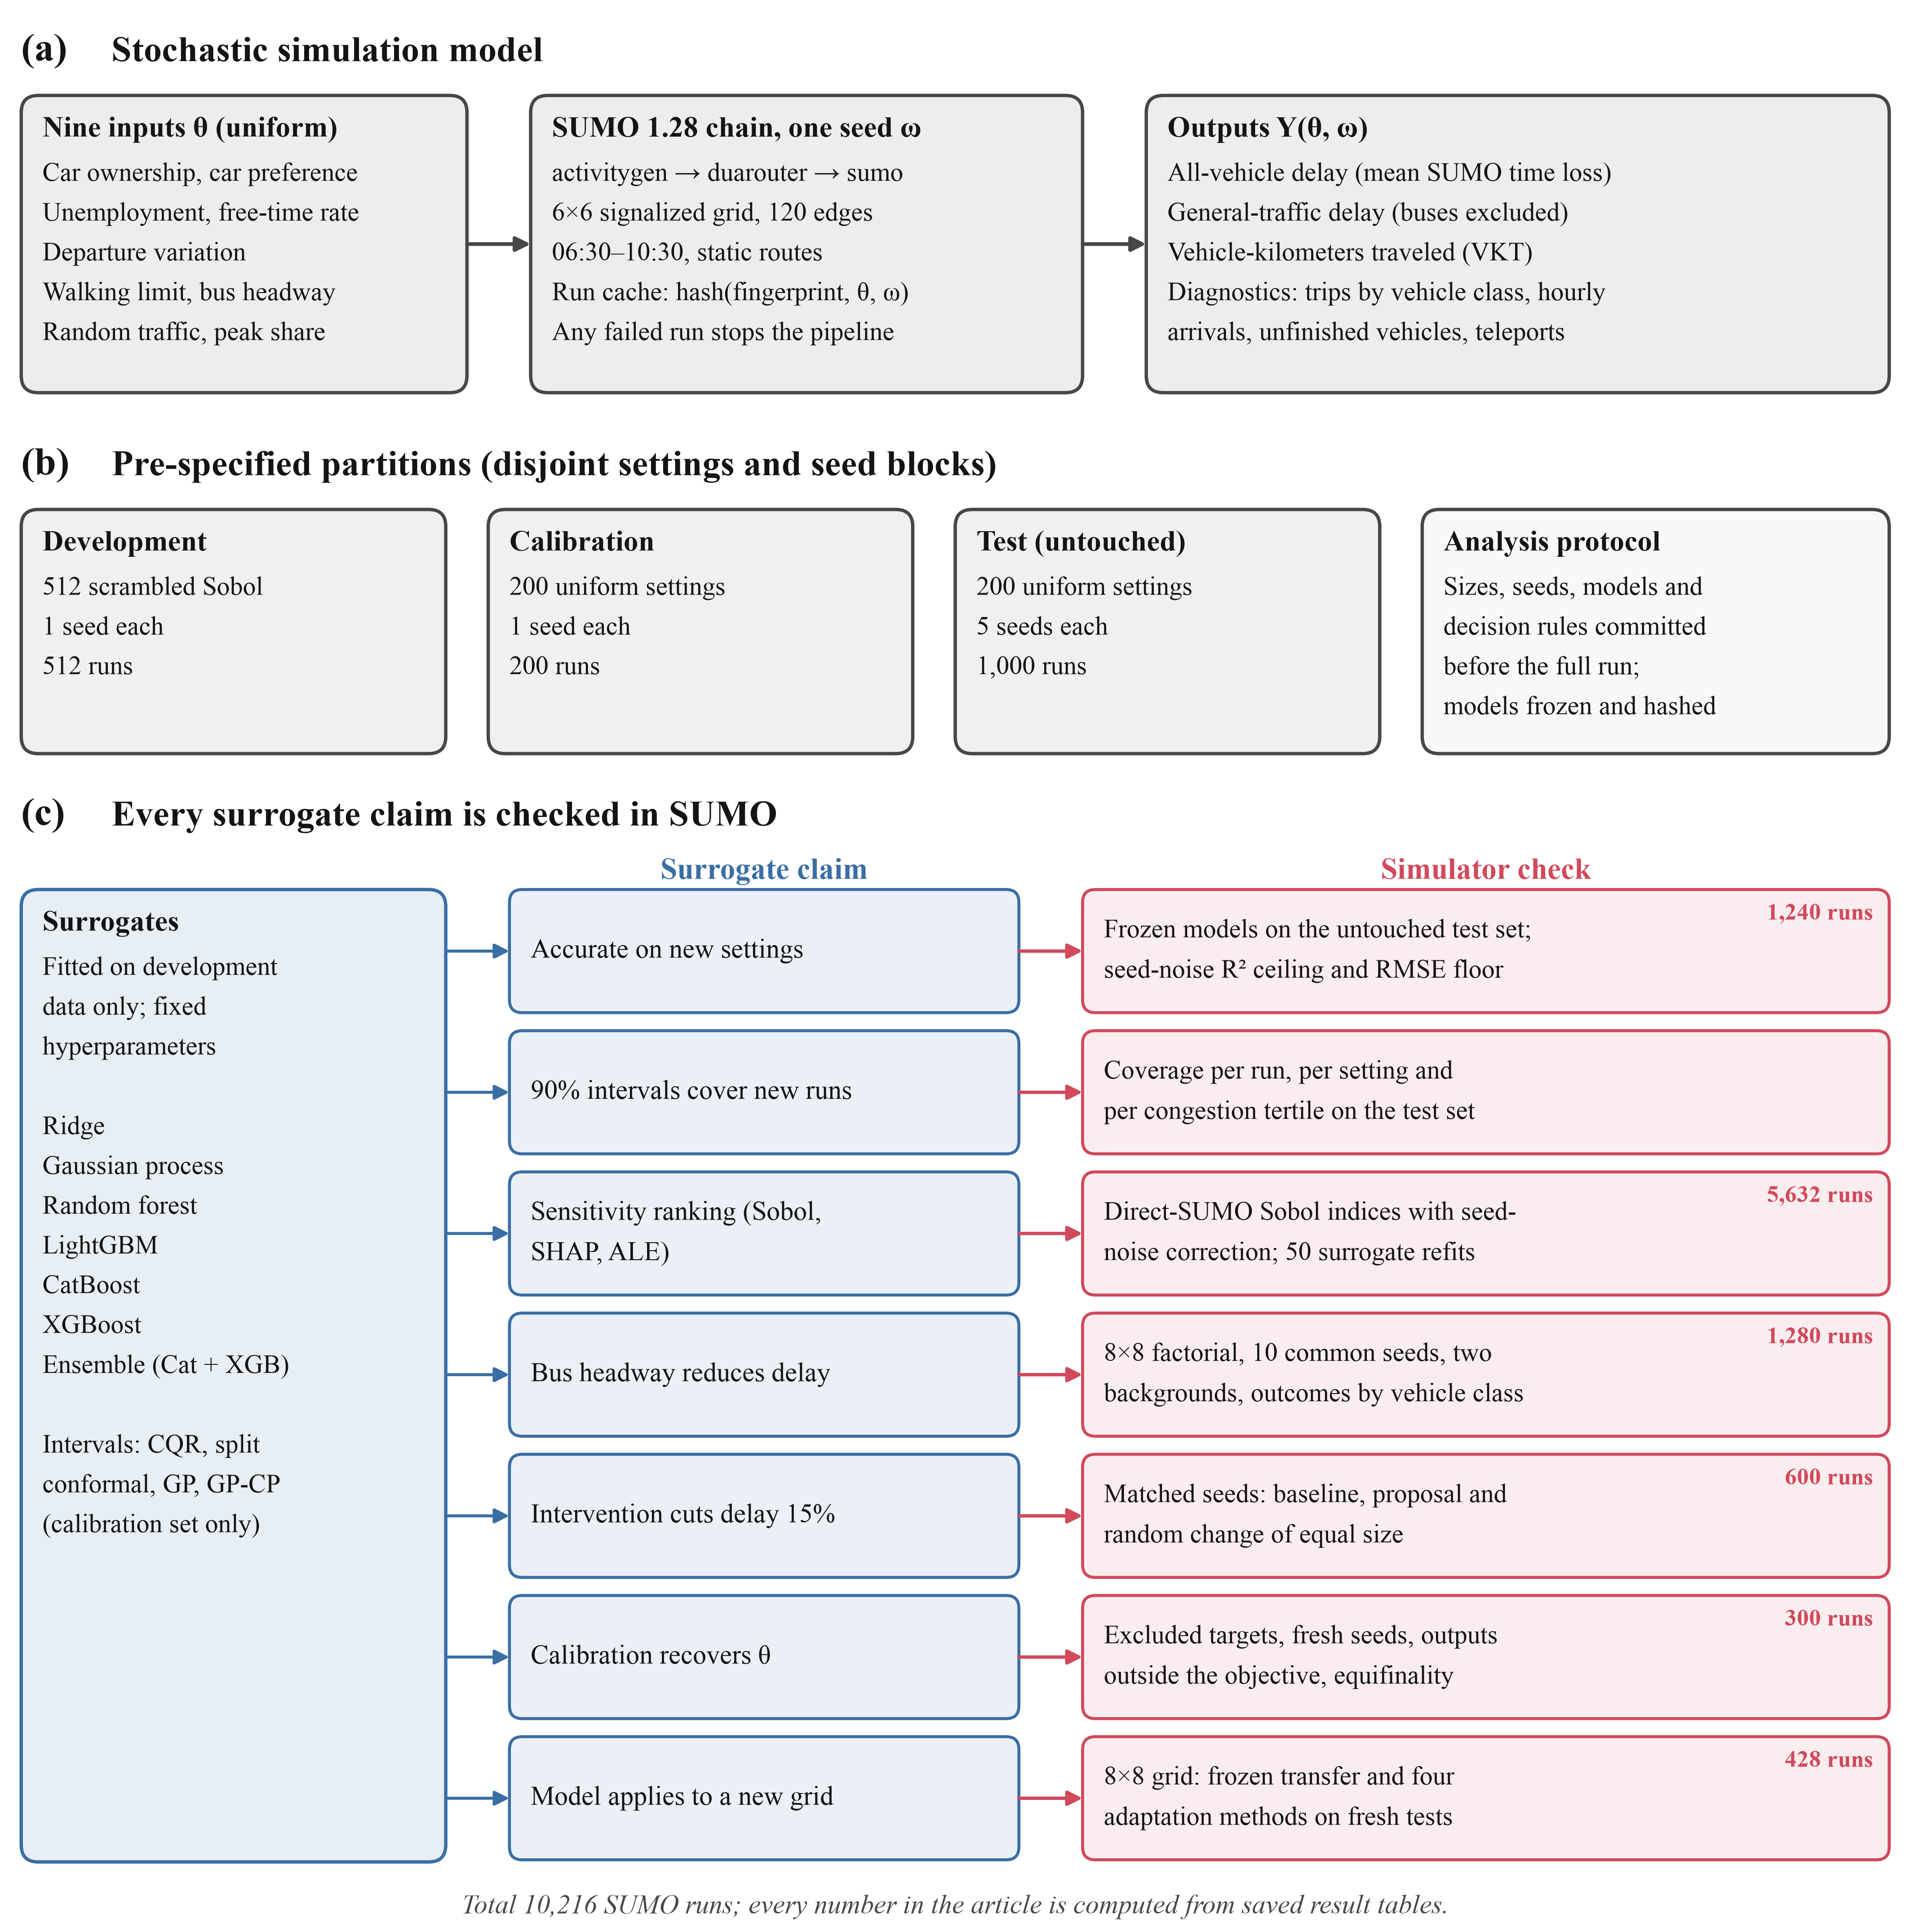

{
 "n_train": 512,
 "n_cal": 200,
 "n_test": 200,
 "test_seeds": 5,
 "n_rep": 24,
 "rep_seeds": 10,
 "n_recourse": 20,
 "policy_seeds": 10,
 "search_budget": 6000,
 "n_targets": 10,
 "target_seeds": 10,
 "calib_trials": 600,
 "mech_levels": 8,
 "mech_seeds": 10,
 "mech_backgrounds": 2,
 "sobol_sim_power": 9,
 "saltelli_power": 11,
 "n_boot": 50,
 "n_transfer": 100,
 "n_adapt": 128,
 "n_adapt_cal": 100,
 "n_adapt_test": 100,
 "n_teleport": 24,
 "model_size": 500
}


,low,high
carRate,0.20,0.90
carPreference,0.10,0.95
unemploymentRate,0.02,0.25
freeTimeActivityRate,0.05,0.50
departureVariation,60.00,1800.00
footDistanceLimit,150.00,1200.00
busHeadway,300.00,2400.00
uniformRandomTraffic,0.01,0.35
morningPeakProp,0.30,0.85


In [2]:
import pandas as pd, json
from IPython.display import Image, display
from sumo_study.workflow import Study, STAGES
from sumo_study.config import PROFILES, BOUNDS
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
display(Image(filename=str(REPO / "results" / "full" / "figures" / "png" / "Fig01_methodological_framework.png"), width=900))
PROFILE, WORKERS = "full", 8
study = Study(REPO / "results", profile=PROFILE, workers=WORKERS)
print(json.dumps(PROFILES[PROFILE], indent=1)); pd.DataFrame(BOUNDS, index=["low", "high"]).T

In [3]:
def ensure(stage):
    """Run a stage only if it has not completed (results and SUMO runs are cached)."""
    if study.status.get(stage, {}).get("status") != "complete":
        study.run(stage)
    else:
        print(f"{stage}: complete ({study.status[stage].get('elapsed_sec', '?')} s)")
T = study.load
def fig(name, width=1400):
    """Show a downscaled preview; full-resolution files are in results/<profile>/figures/."""
    import io
    from PIL import Image as PILImage
    im = PILImage.open(study.root / "figures" / "png" / f"{name}.png")
    im.thumbnail((width, width))
    buf = io.BytesIO(); im.convert("RGB").save(buf, format="JPEG", quality=85)
    display(Image(data=buf.getvalue(), format="jpeg", width=900))

## 3. Partitioned designs and simulations
Development: scrambled Sobol. Calibration and test: independent uniform samples over the same domain, disjoint, with their own seed blocks; every test setting is run with 5 seeds.

In [4]:
ensure('design')
display(T('simulation_audit').groupby('experiment').size().rename('runs').to_frame())
T('design_nearest_neighbour_distance').groupby('split').describe().T

design: complete (653.0 s)


,runs
experiment,
adapt_calibration_runs_grid8,100
adapt_runs_grid8,128
adapt_test_runs_grid8,100
calibration,200
inverse_target_runs,100
inverse_validation_runs,200
mechanism_runs,1280
recourse_runs,600
replication_runs,240


split                       calibration     test
nn_distance_to_train count      200.000  200.000
                     mean         0.478    0.473
                     std          0.078    0.085
                     min          0.218    0.236
                     25%          0.430    0.428
                     50%          0.475    0.474
                     75%          0.526    0.532
                     max          0.650    0.661

## 4. Development cross-validation and frozen surrogates
Fixed hyperparameters; models are hashed in `models/freeze_record.json` before calibration or test outcomes are read.

In [5]:
ensure('models')
T('dev_cv_summary').pivot(index='model', columns='target', values='R2_mean')

models: complete (78.4 s)


target,general_time_loss_sec,mean_time_loss_sec,total_vkt_km
model,,,
CatBoost,0.897,0.919,0.986
Ensemble,0.904,0.922,0.981
GaussianProcess,0.921,0.925,0.994
LightGBM,0.907,0.917,0.972
RandomForest,0.890,0.898,0.948
Ridge,0.369,0.436,0.944
XGBoost,0.900,0.916,0.970


## 5. Independent test of frozen surrogates
Single-run and seed-mean estimands; paired bootstrap error differences.

independent_test: complete (0.4 s)


target,general_time_loss_sec,mean_time_loss_sec,total_vkt_km
model,,,
CatBoost,0.942,0.936,0.992
Ensemble,0.941,0.937,0.991
GaussianProcess,0.951,0.938,0.995
LightGBM,0.937,0.931,0.982
RandomForest,0.924,0.901,0.963
Ridge,0.417,0.478,0.945
XGBoost,0.935,0.930,0.986


,source,target,settings,seeds_per_setting,within_SD,between_SD,noise_share,R2_ceiling_single_run,RMSE_floor_single_run,ICC
0,test settings,mean_time_loss_sec,200,5.0,1.608,9.014,0.031,0.969,1.608,0.969
1,test settings,total_vkt_km,200,5.0,36.792,670.203,0.003,0.997,36.792,0.997
2,test settings,general_time_loss_sec,200,5.0,1.652,8.406,0.037,0.963,1.652,0.963


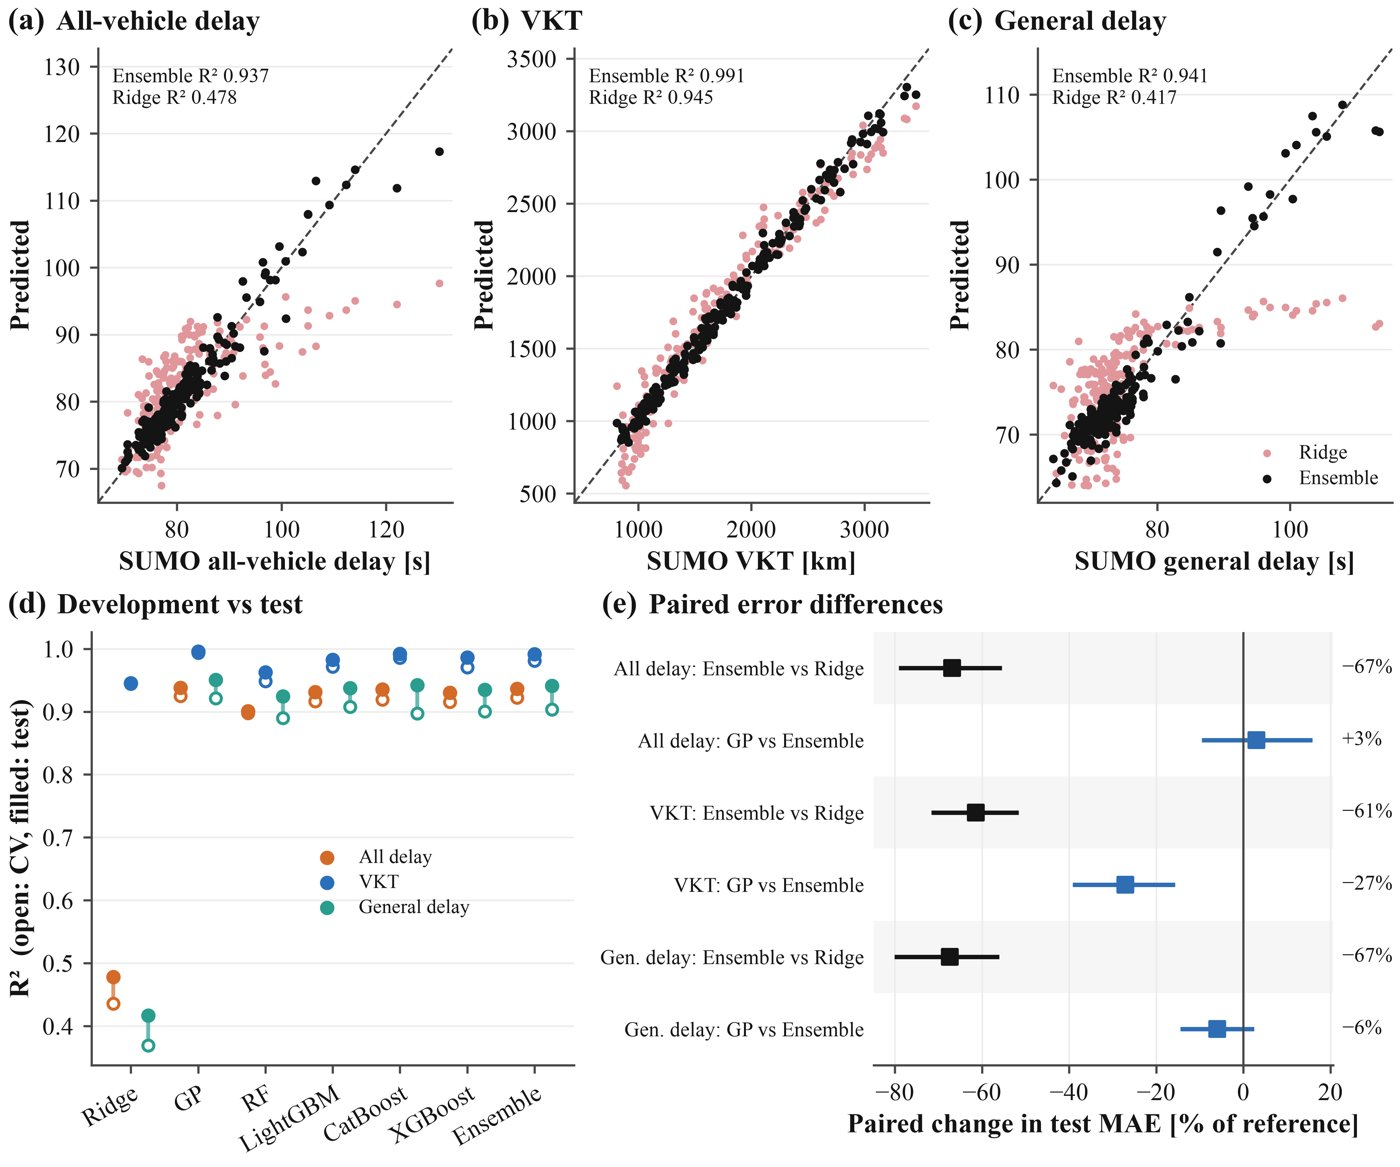

In [6]:
ensure('independent_test')
tm = T('test_metrics'); display(tm[tm.estimand=='single_run'].pivot(index='model', columns='target', values='R2'))
display(T('noise_test_settings'))
fig('Fig05_independent_test')

## 6. Predictive intervals: train → calibrate → test
CQR, split conformal, native GP and GP-normalised conformal at 90% nominal.

intervals: complete (0.8 s)


,target,method,estimand,coverage,CI_low,CI_high,mean_width
0,mean_time_loss_sec,CQR,single_run,0.900,0.851,0.934,11.242
2,mean_time_loss_sec,CQR,new_runs,0.883,0.852,0.911,11.242
3,mean_time_loss_sec,SplitCP,single_run,0.895,0.845,0.930,6.080
5,mean_time_loss_sec,SplitCP,new_runs,0.877,0.845,0.905,6.080
6,mean_time_loss_sec,GP,single_run,0.890,0.839,0.926,6.596
8,mean_time_loss_sec,GP,new_runs,0.877,0.843,0.910,6.596
9,mean_time_loss_sec,GP-CP,single_run,0.875,0.822,0.914,5.985
11,mean_time_loss_sec,GP-CP,new_runs,0.852,0.816,0.886,5.985
12,total_vkt_km,CQR,single_run,0.870,0.816,0.910,788.777
14,total_vkt_km,CQR,new_runs,0.868,0.824,0.907,788.777


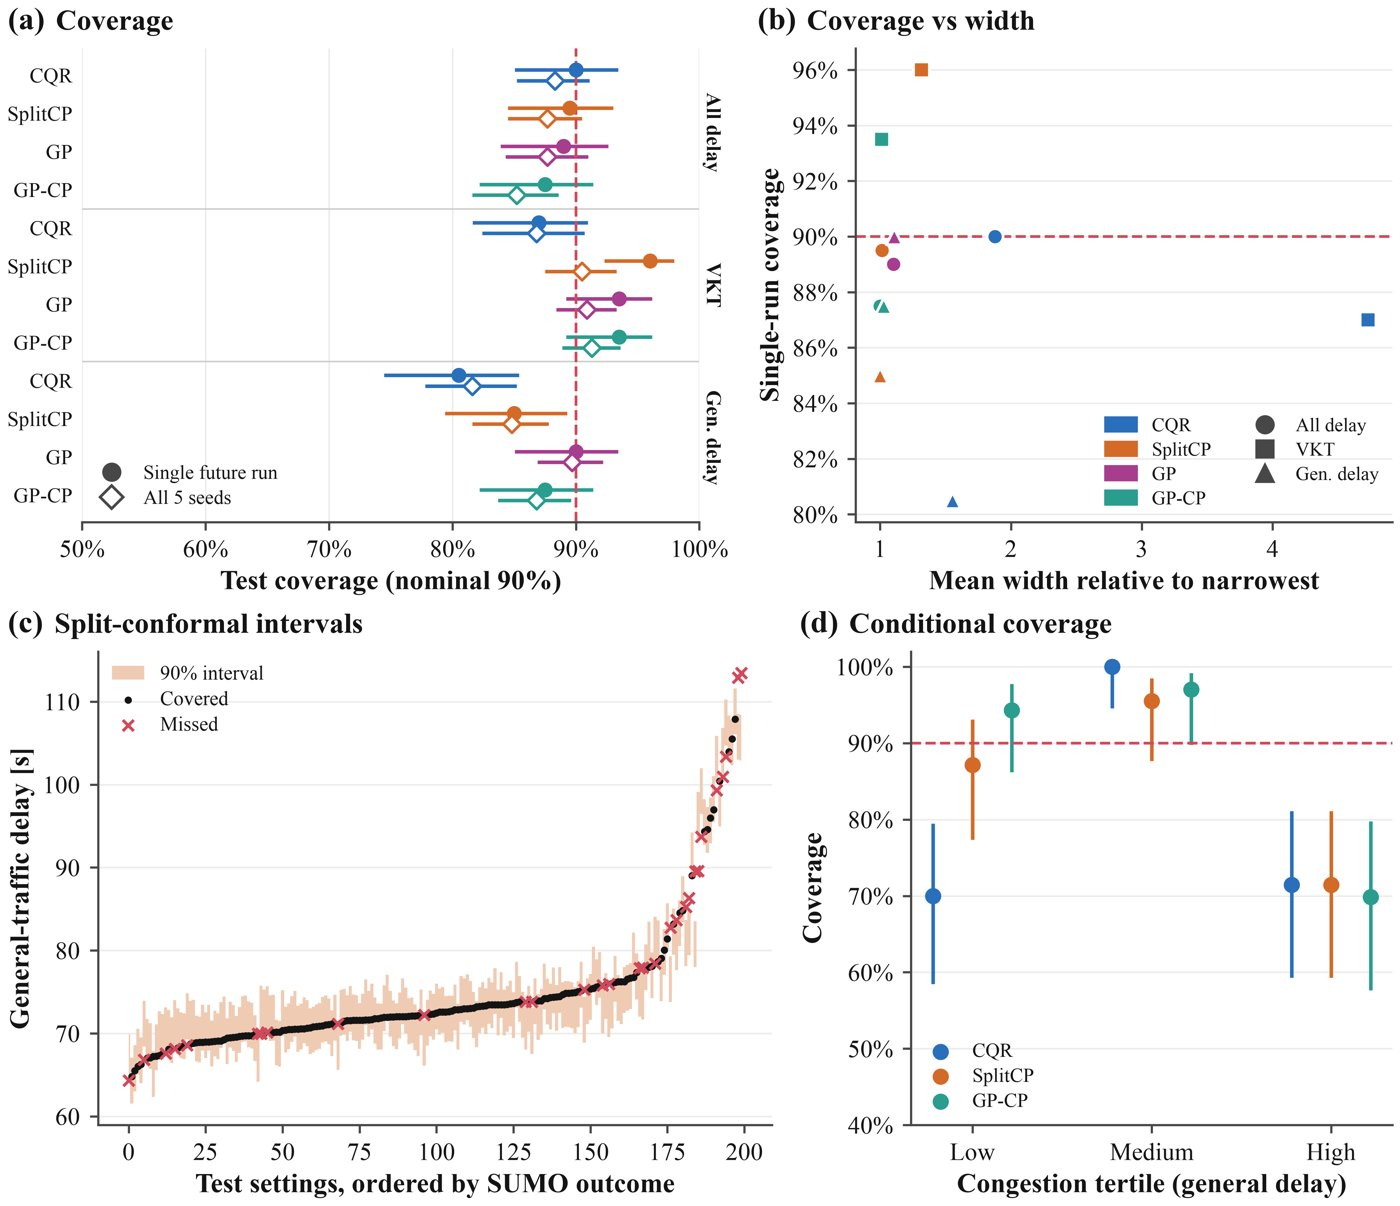

In [7]:
ensure('intervals')
c = T('interval_coverage'); display(c[c.estimand!='seed_mean'][['target','method','estimand','coverage','CI_low','CI_high','mean_width']])
fig('Fig06_predictive_intervals')

## 7. Repeated-seed replication
24 development settings spanning the delay range × 10 seeds.

replication: complete (92.6 s)


,source,target,settings,seeds_per_setting,within_SD,between_SD,noise_share,R2_ceiling_single_run,RMSE_floor_single_run,ICC
0,replicated development settings,mean_time_loss_sec,24,10.0,1.434,11.580,0.015,0.985,1.434,0.985
1,replicated development settings,total_vkt_km,24,10.0,41.203,782.240,0.003,0.997,41.203,0.997
2,replicated development settings,general_time_loss_sec,24,10.0,1.504,9.006,0.027,0.973,1.504,0.973
3,replicated development settings,total_completed_trips,24,10.0,24.125,600.771,0.002,0.998,24.125,0.998
4,replicated development settings,p90_time_loss_sec,24,10.0,4.298,28.607,0.022,0.978,4.298,0.978


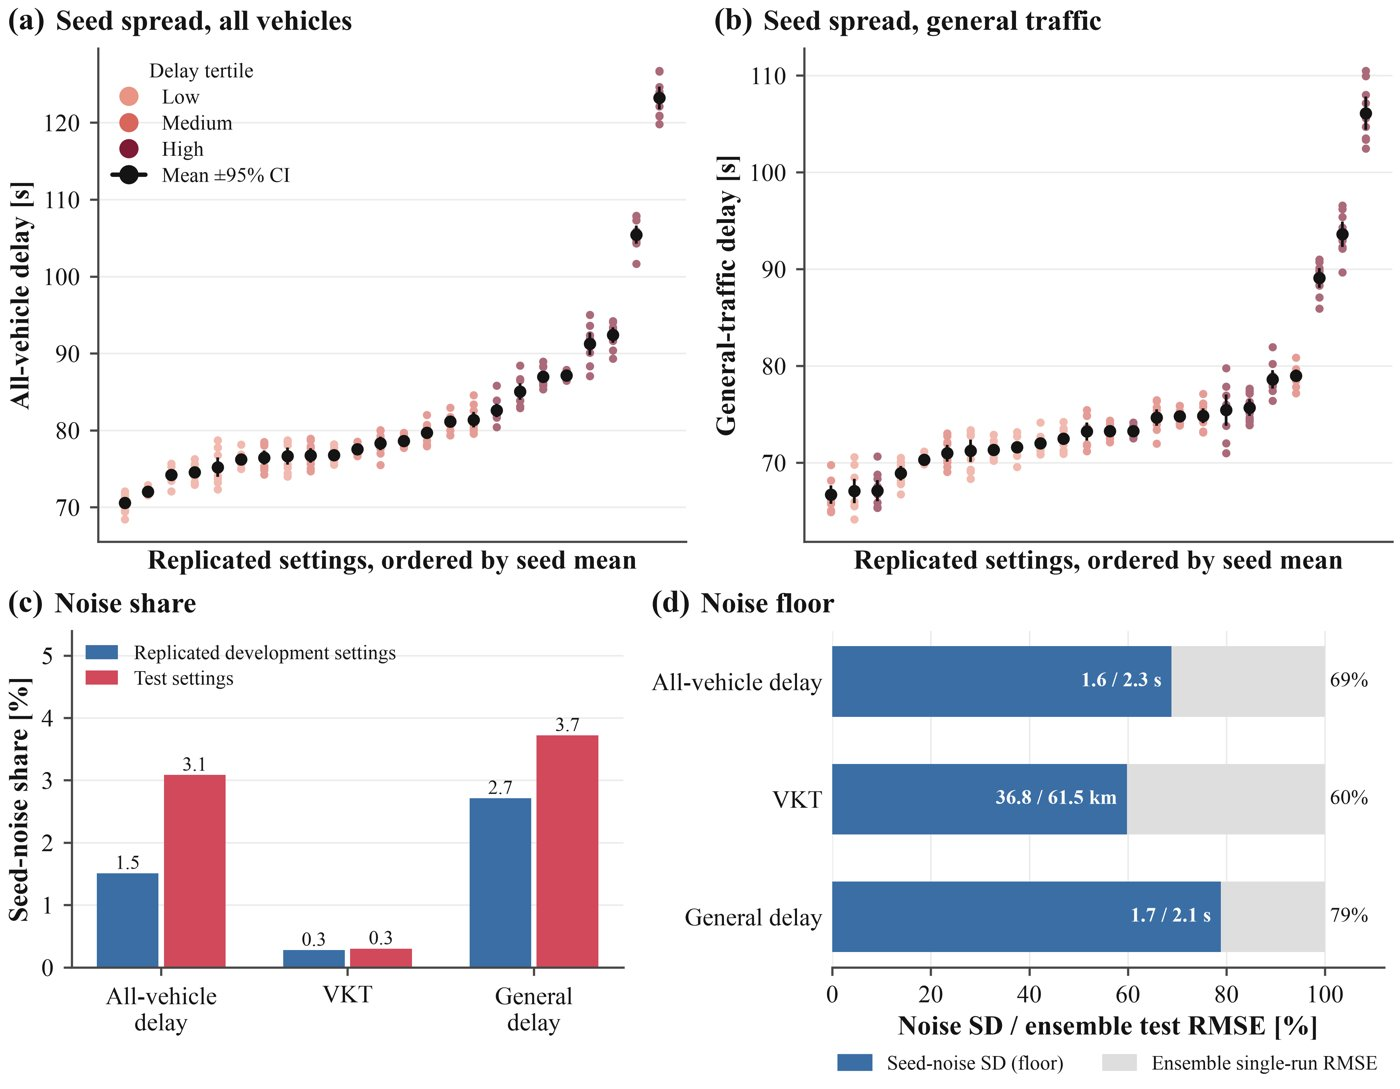

In [8]:
ensure('replication')
display(T('noise_replication'))
fig('Fig03_simulation_noise')

## 8. Surrogate-proposed interventions validated in SUMO
Surrogate proposals re-simulated with 10 matched seeds against the baseline and a random same-distance control.

recourse: complete (248.6 s)


,arm,scenarios,mean_achieved,median_achieved,delay_target_rate,joint_rate,mean_general_reduction,general_target_rate,mean_completion_ratio,mean_predicted
0,random,20,6.769,5.893,0.2,0.2,7.090,0.2,0.992,6.453
1,recourse,20,15.756,15.298,0.5,0.5,17.052,0.6,1.000,16.992


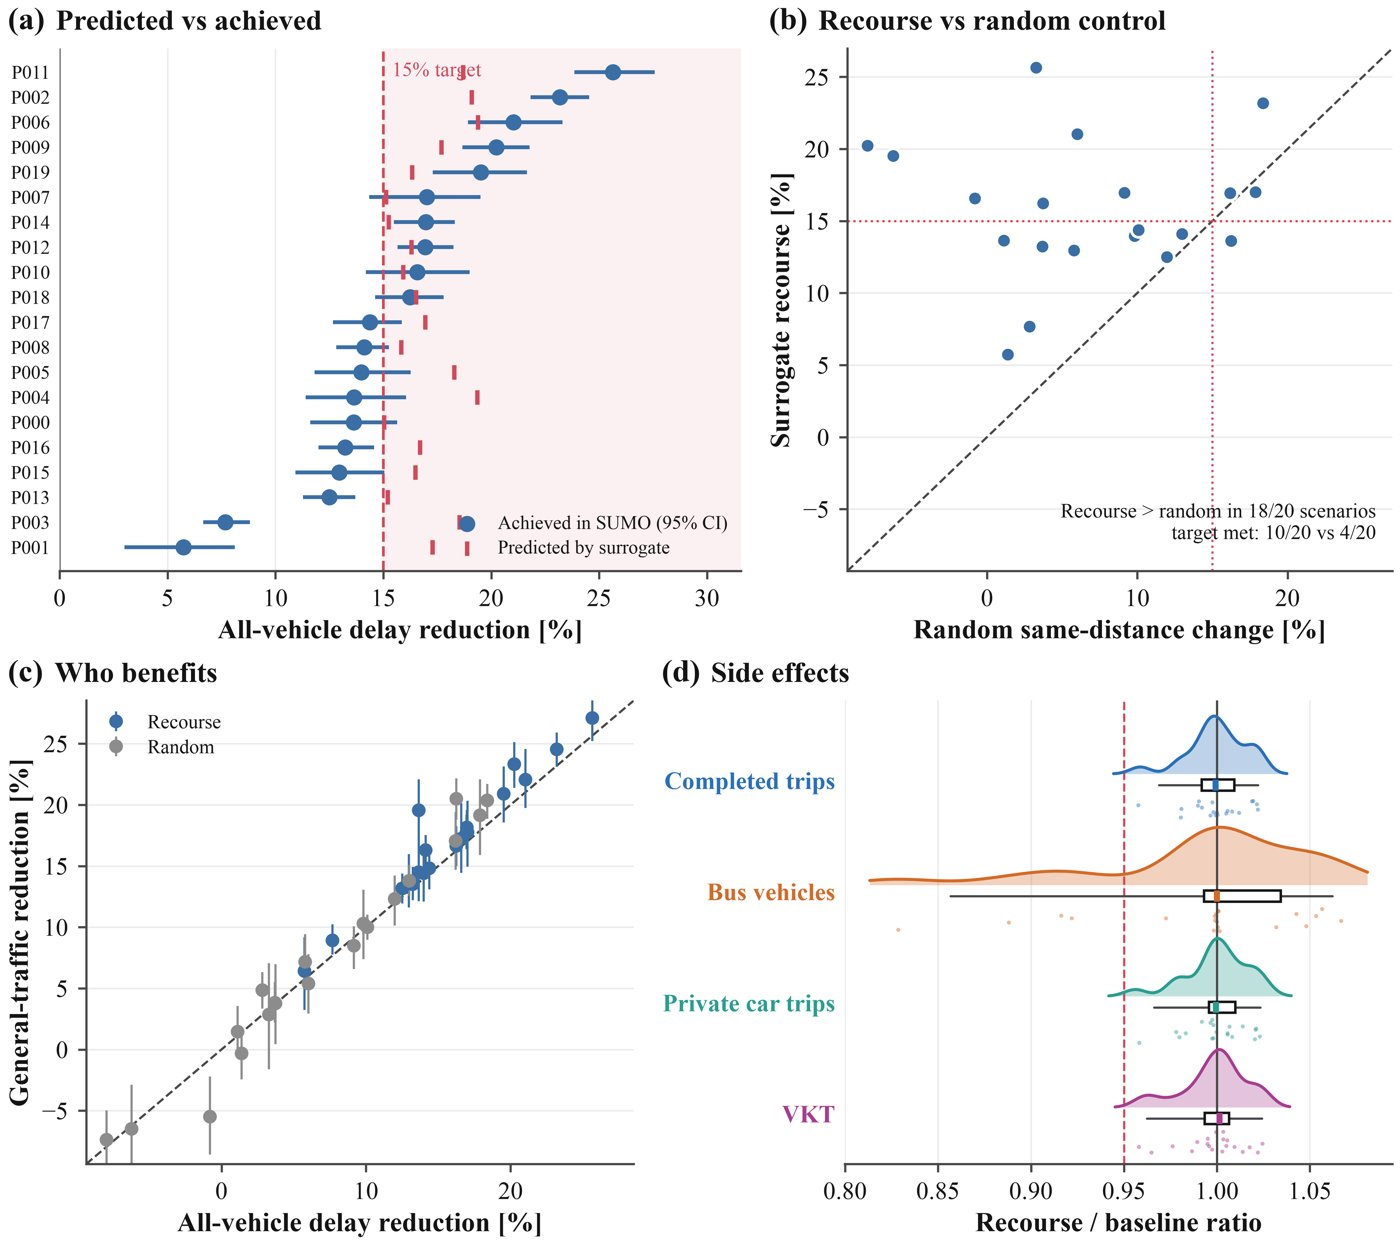

In [9]:
ensure('recourse')
display(T('recourse_overview'))
fig('Fig10_recourse_validation')

## 9. Inverse calibration on excluded targets
Two objectives; fresh-seed re-simulation; dense equifinality scan.

inverse_calibration: complete (374.3 s)


objective,Aggregate (2 outputs),Extended (8 outputs)
parameter,,
busHeadway,0.282,0.163
carPreference,0.350,0.314
carRate,0.240,0.156
departureVariation,0.251,0.279
footDistanceLimit,0.102,0.060
freeTimeActivityRate,0.400,0.296
morningPeakProp,0.281,0.032
unemploymentRate,0.243,0.128
uniformRandomTraffic,0.305,0.123


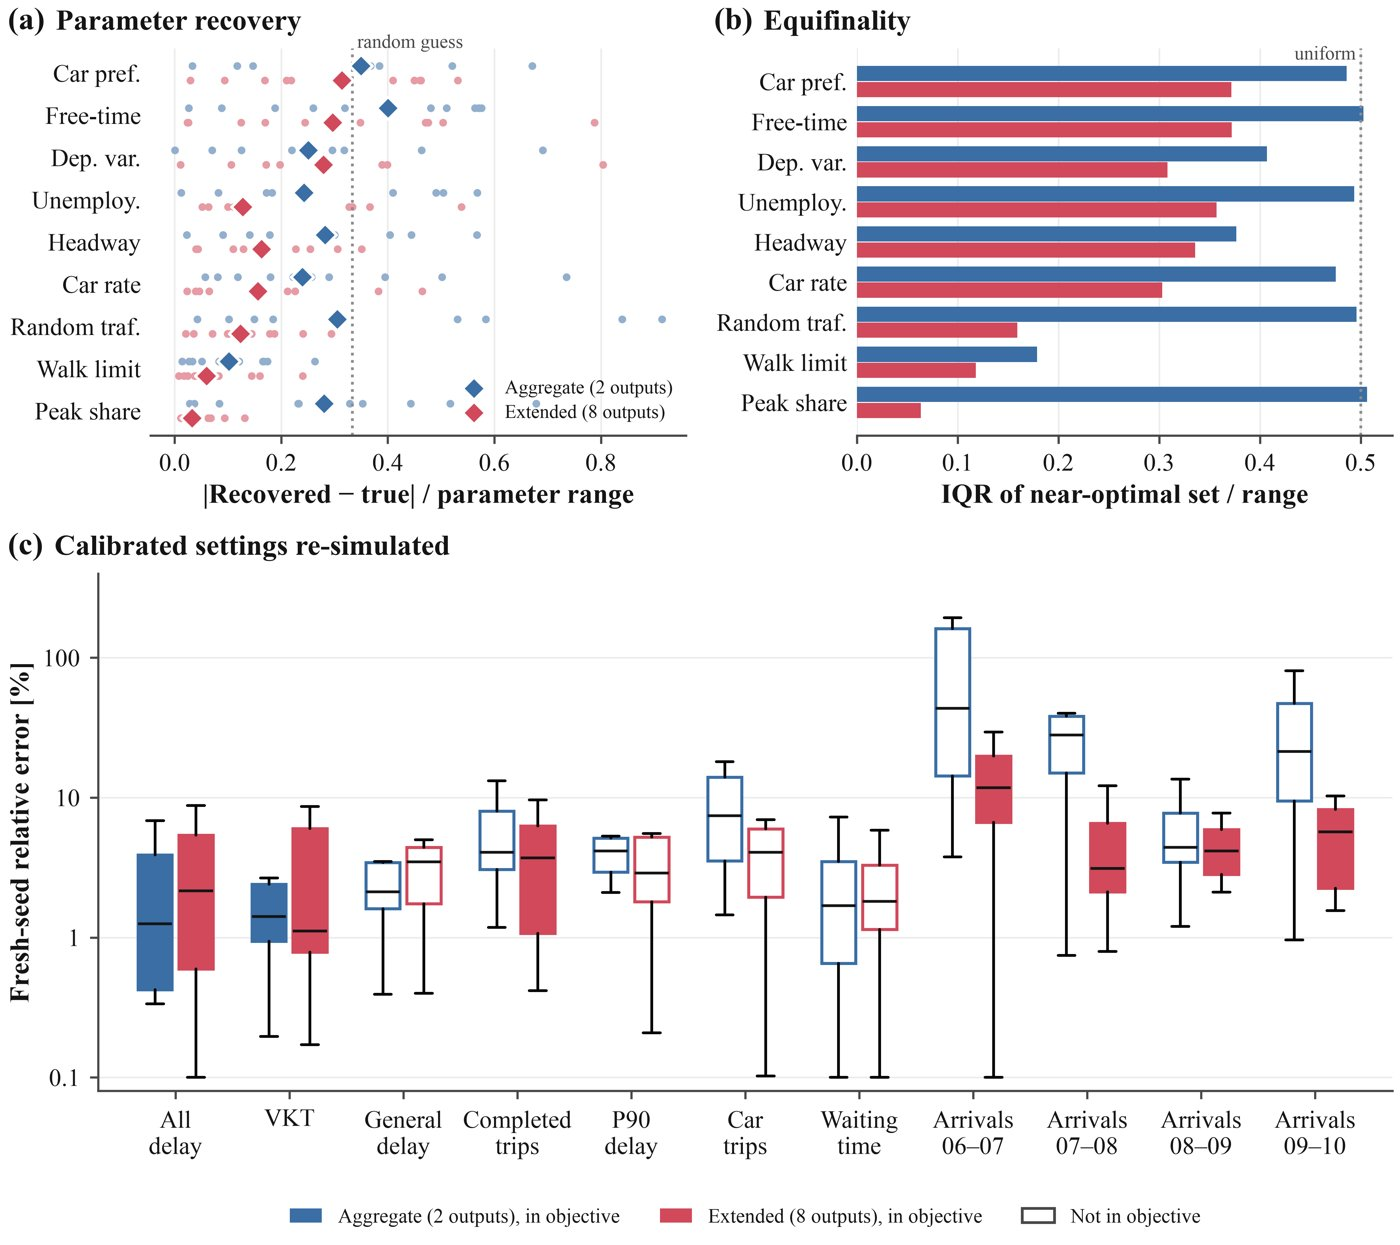

In [10]:
ensure('inverse_calibration')
display(T('inverse_parameter_recovery').groupby(['objective','parameter']).abs_error.median().unstack(0))
fig('Fig11_inverse_calibration')

## 10. Headway × departure-variation factorial
8×8 levels × 10 common seeds at two backgrounds; outcomes separated by vehicle type.

mechanism: complete (614.2 s)


component                           busHeadway  departureVariation  interaction
background   outcome                                                           
car-oriented general_time_loss_sec   1.246e-04               0.999        0.001
             mean_time_loss_sec      1.375e-01               0.861        0.001
midpoint     general_time_loss_sec   9.732e-05               0.999        0.001
             mean_time_loss_sec      2.103e-01               0.789        0.001

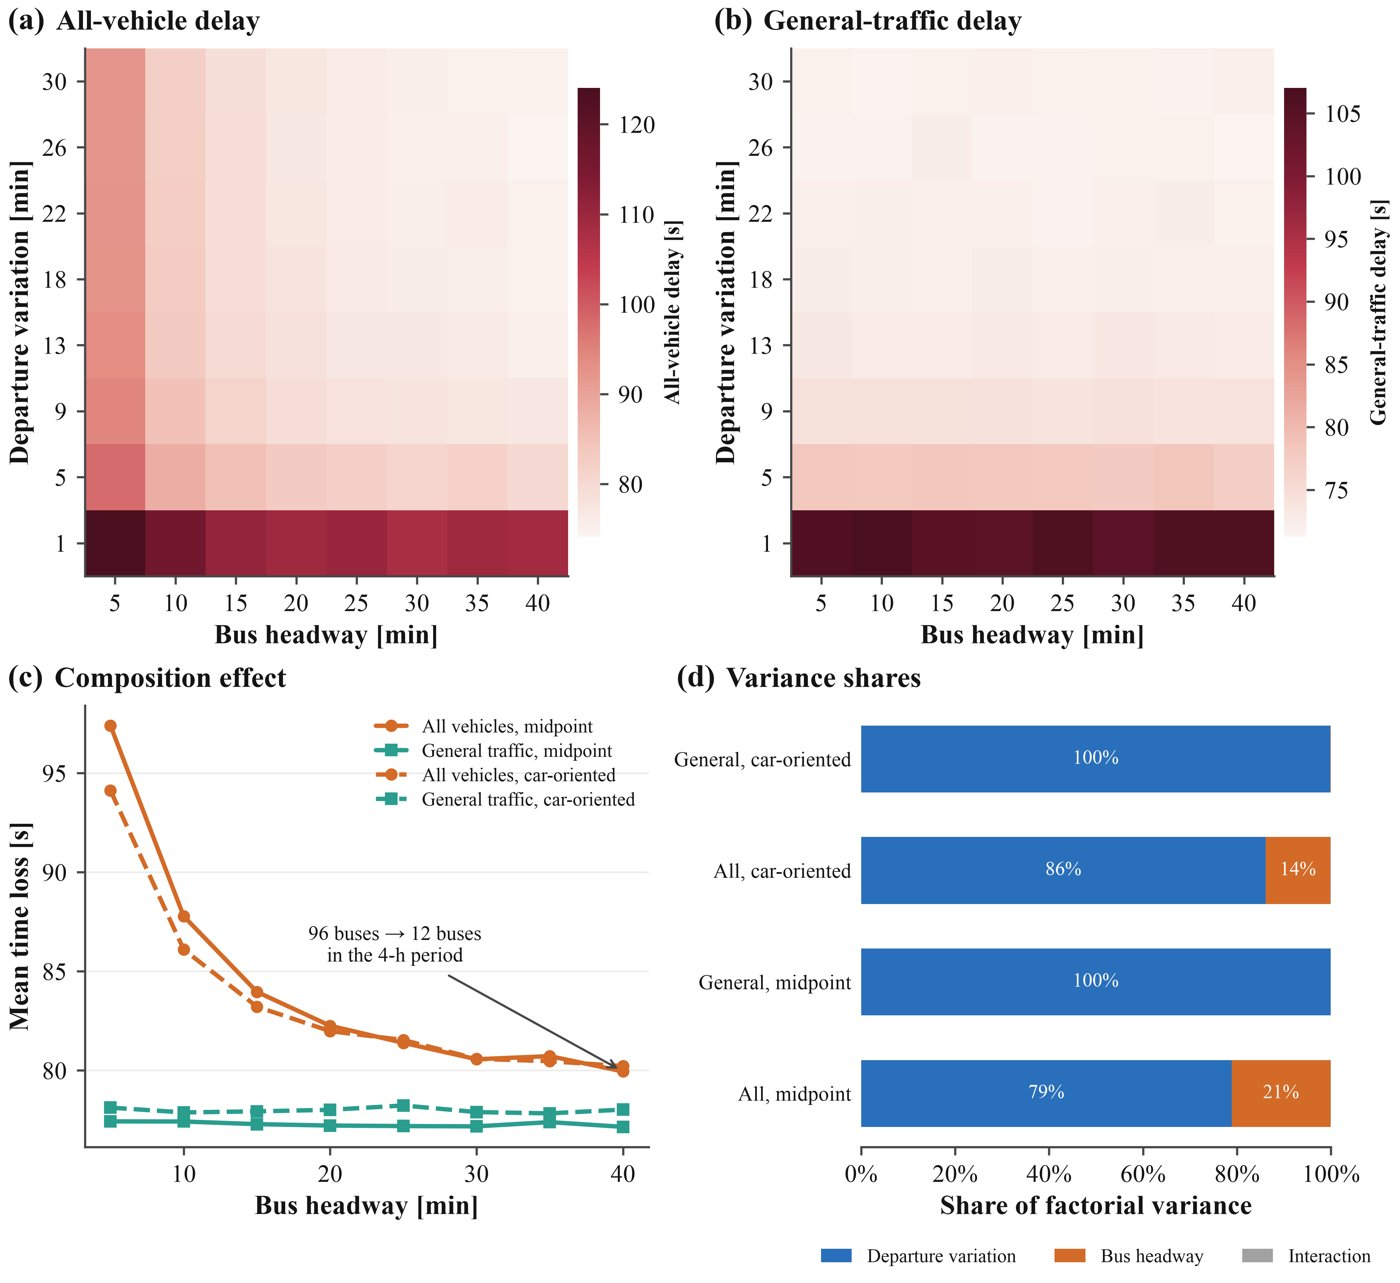

In [11]:
ensure('mechanism')
display(T('mechanism_variance_shares').pivot_table(index=['background','outcome'], columns='component', values='share'))
fig('Fig09_headway_mechanism')

## 11. Direct-SUMO Sobol indices
Radial A/B/AB_i design on the simulator itself; seed-noise-corrected estimators.

In [12]:
ensure('sobol_sumo')
s = T('sobol_sumo_indices'); s.pivot_table(index='parameter', columns=['target','estimator'], values='ST').round(3)

sobol_sumo: complete (2552.5 s)


target               general_time_loss_sec                                   mean_time_loss_sec                                         total_vkt_km           \
estimator             SUMO noise-corrected SUMO raw Surrogate, same design SUMO noise-corrected SUMO raw Surrogate, same design SUMO noise-corrected SUMO raw   
parameter                                                                                                                                                       
busHeadway                           0.014    0.043                  0.001                0.207    0.223                  0.197                0.017    0.021   
carPreference                        0.033    0.061                  0.012                0.018    0.039                  0.003                0.023    0.026   
carRate                              0.023    0.052                  0.009                0.024    0.045                  0.014                0.116    0.120   
departureVariation                   0.982    0.983                  0.945                0.739    0.744                  0.769               -0.000    0.004   
footDistanceLimit                    0.074    0.101                  0.043                0.076    0.095                  0.040                0.851    0.851   
freeTimeActivityRate                 0.008    0.037                  0.000                0.009    0.029                  0.001                0.001    0.004   
morningPeakProp                      0.041    0.069                  0.007                0.030    0.050                  0.006                0.003    0.007   
unemploymentRate                     0.020    0.049                  0.003                0.014    0.035                  0.001                0.012    0.016   
uniformRandomTraffic                 0.023    0.051                  0.006                0.025    0.045                  0.013                0.016    0.020   

target                                       
estimator            Surrogate, same design  
parameter                                    
busHeadway                            0.014  
carPreference                         0.020  
carRate                               0.107  
departureVariation                    0.000  
footDistanceLimit                     0.857  
freeTimeActivityRate                  0.001  
morningPeakProp                       0.002  
unemploymentRate                      0.010  
uniformRandomTraffic                  0.013

## 12. Surrogate sensitivity, refit stability, SHAP, ALE, DML
50 bootstrap refits of the ensemble; interventional ensemble TreeSHAP; ALE with refit bands.

sensitivity: complete (260.7 s)


,kendall_tau,top2_same
target,,
general_time_loss_sec,0.927,1.0
mean_time_loss_sec,0.920,1.0
total_vkt_km,0.958,1.0


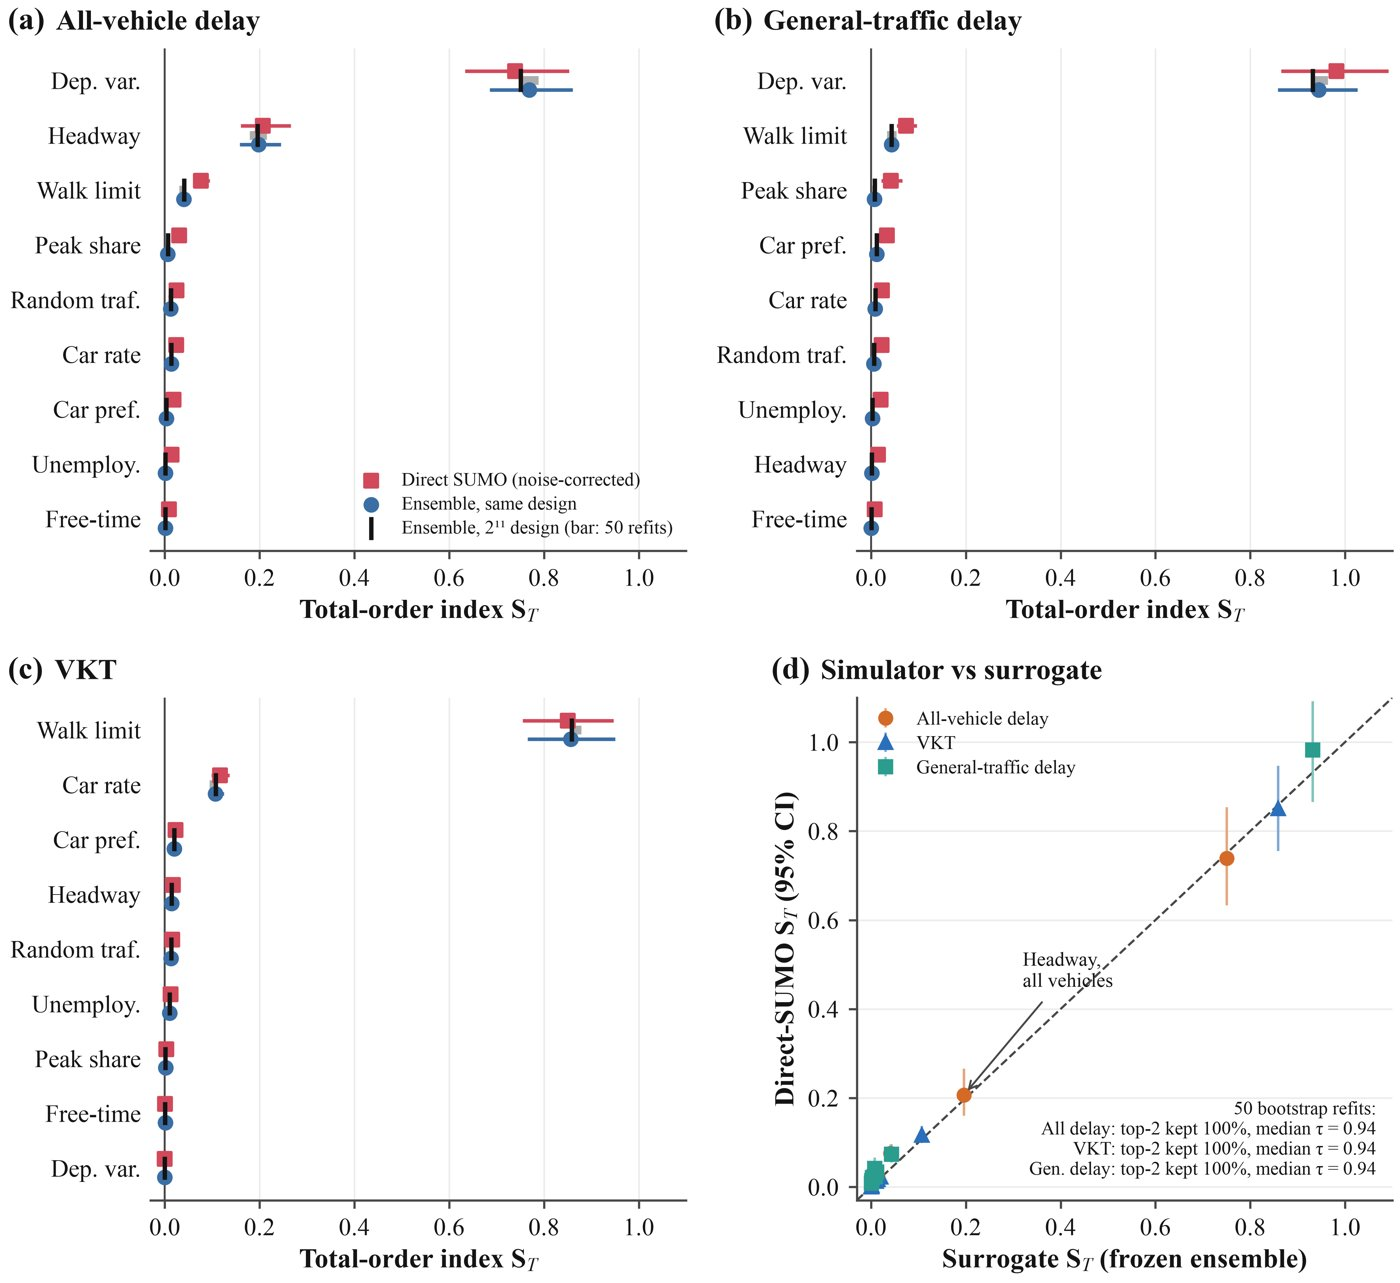

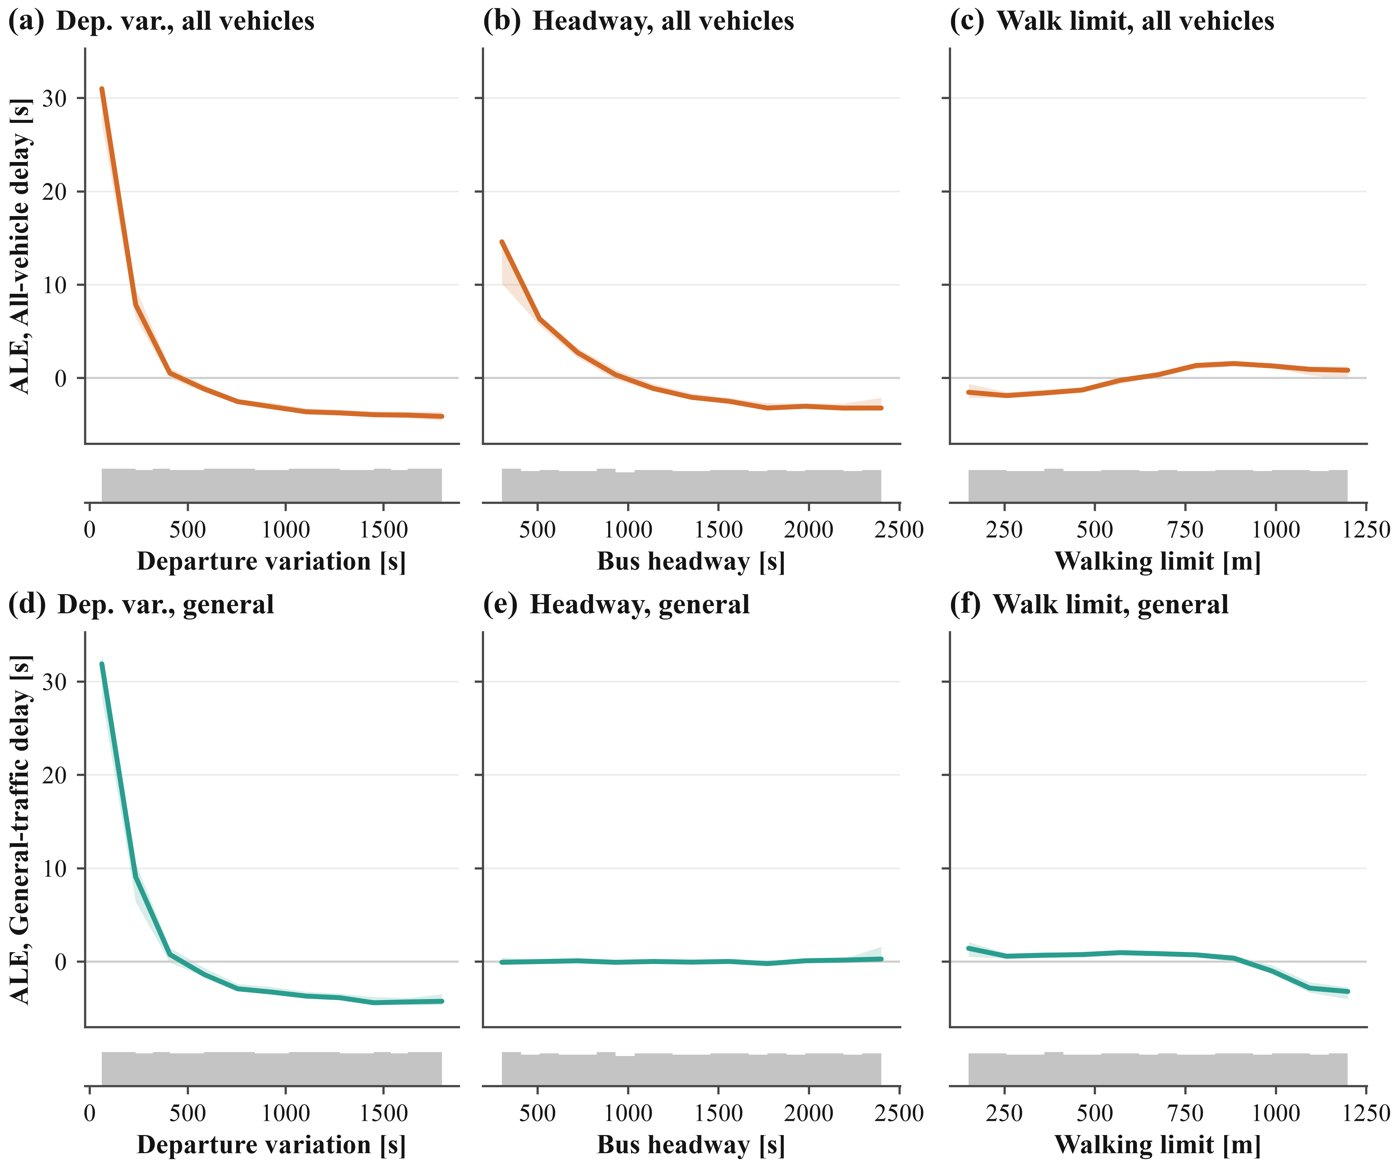

In [13]:
ensure('sensitivity')
display(T('sobol_rank_stability').groupby('target')[['kendall_tau','top2_same']].mean())
fig('Fig07_sobol_sensitivity'); fig('Fig08_ALE_response_shapes')

## 13. Learning curve against the noise floor
Development folds only.

learning_curve: complete (153.4 s)


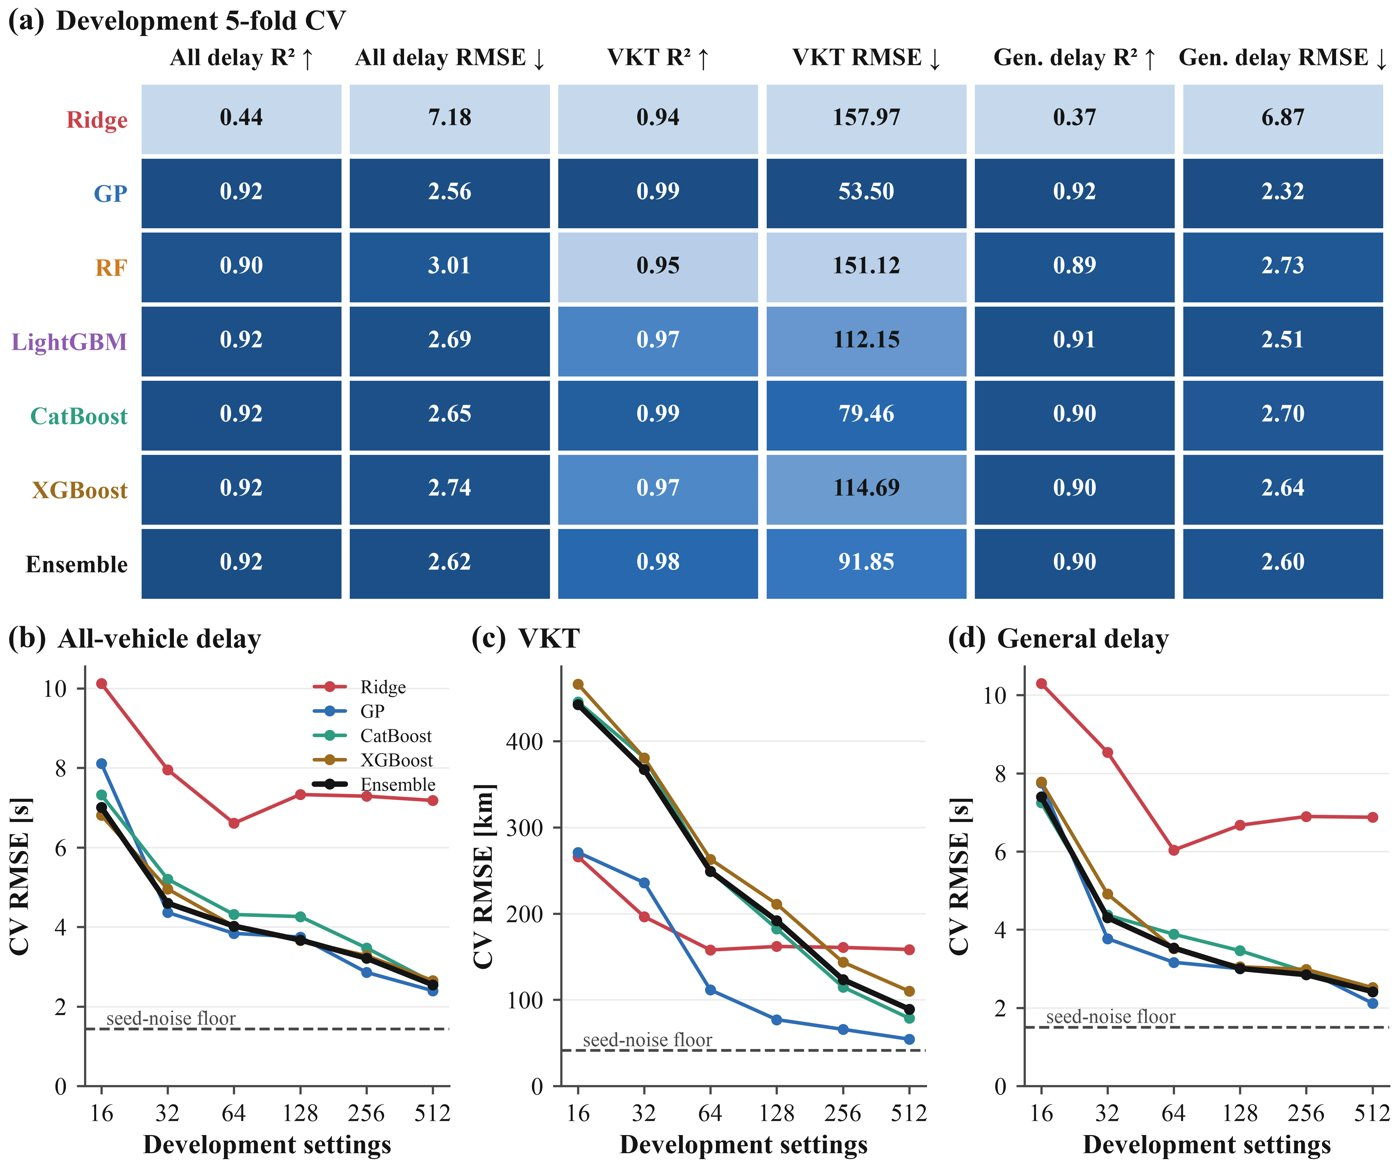

In [14]:
ensure('learning_curve')
fig('Fig04_development_and_learning')

## 14a. Teleport rule
Same settings and seeds with teleporting disabled.

In [15]:
ensure('teleport')
T('teleport_pairs')

teleport: complete (16.9 s)


,setting_id,mean_time_loss_sec_tp300,total_vkt_km_tp300,total_completed_trips_tp300,unfinished_trips_tp300,stat_teleports_total_tp300,mean_time_loss_sec_off,total_vkt_km_off,total_completed_trips_off,unfinished_trips_off,stat_teleports_total_off
0,train_0460,68.378,2875.126,2251,4,0.0,68.378,2875.126,2251,4,0.0
1,train_0387,72.422,3272.622,2442,3,0.0,72.422,3272.622,2442,3,0.0
2,train_0196,73.483,2428.426,1715,2,0.0,73.483,2428.426,1715,2,0.0
3,train_0146,74.279,2807.955,2046,5,0.0,74.279,2807.955,2046,5,0.0
4,train_0052,74.900,1035.906,683,3,0.0,74.900,1035.906,683,3,0.0
5,train_0171,75.455,2003.452,1356,7,0.0,75.455,2003.452,1356,7,0.0
6,train_0388,75.927,3189.745,2298,3,0.0,75.927,3189.745,2298,3,0.0
7,train_0194,76.322,781.840,518,0,0.0,76.322,781.840,518,0,0.0
8,train_0500,76.734,2519.575,1823,0,0.0,76.734,2519.575,1823,0,0.0
9,train_0287,77.318,2120.886,1436,3,0.0,77.318,2120.886,1436,3,0.0


## 14b. Static vs adaptive rerouting
Median-delay development setting.

In [16]:
ensure('routing')
T('routing_mfd').groupby('mode').mean()

routing: complete (2.7 s)


,time_h,density,flow,speed
mode,,,,
adaptive,8.5,0.326,9.318,42.083
static,8.5,0.388,11.223,41.601


## 14c. Transfer to an 8×8 grid and adaptation
Frozen transfer, then four prespecified adaptation methods.

transfer: complete (387.0 s)


,target,method,R2,RMSE,MAE,bias,MAPE_pct
0,mean_time_loss_sec,Frozen_source,-6.545,30.760,30.264,-30.264,26.695
1,mean_time_loss_sec,Affine_adaptation,0.747,5.637,4.593,-1.177,4.040
2,mean_time_loss_sec,Residual_adaptation,0.927,3.018,2.127,-0.696,1.813
3,mean_time_loss_sec,Target_only,0.884,3.810,2.598,-0.862,2.190
4,total_vkt_km,Frozen_source,-1.361,1248.744,1224.478,-1224.478,42.573
5,total_vkt_km,Affine_adaptation,0.917,234.611,188.620,-10.680,6.574
6,total_vkt_km,Residual_adaptation,0.983,107.431,84.339,-2.585,2.887
7,total_vkt_km,Target_only,0.960,162.422,132.890,-15.668,4.429
8,general_time_loss_sec,Frozen_source,-9.814,31.257,30.671,-30.671,28.836
9,general_time_loss_sec,Affine_adaptation,0.629,5.786,4.867,-1.112,4.575


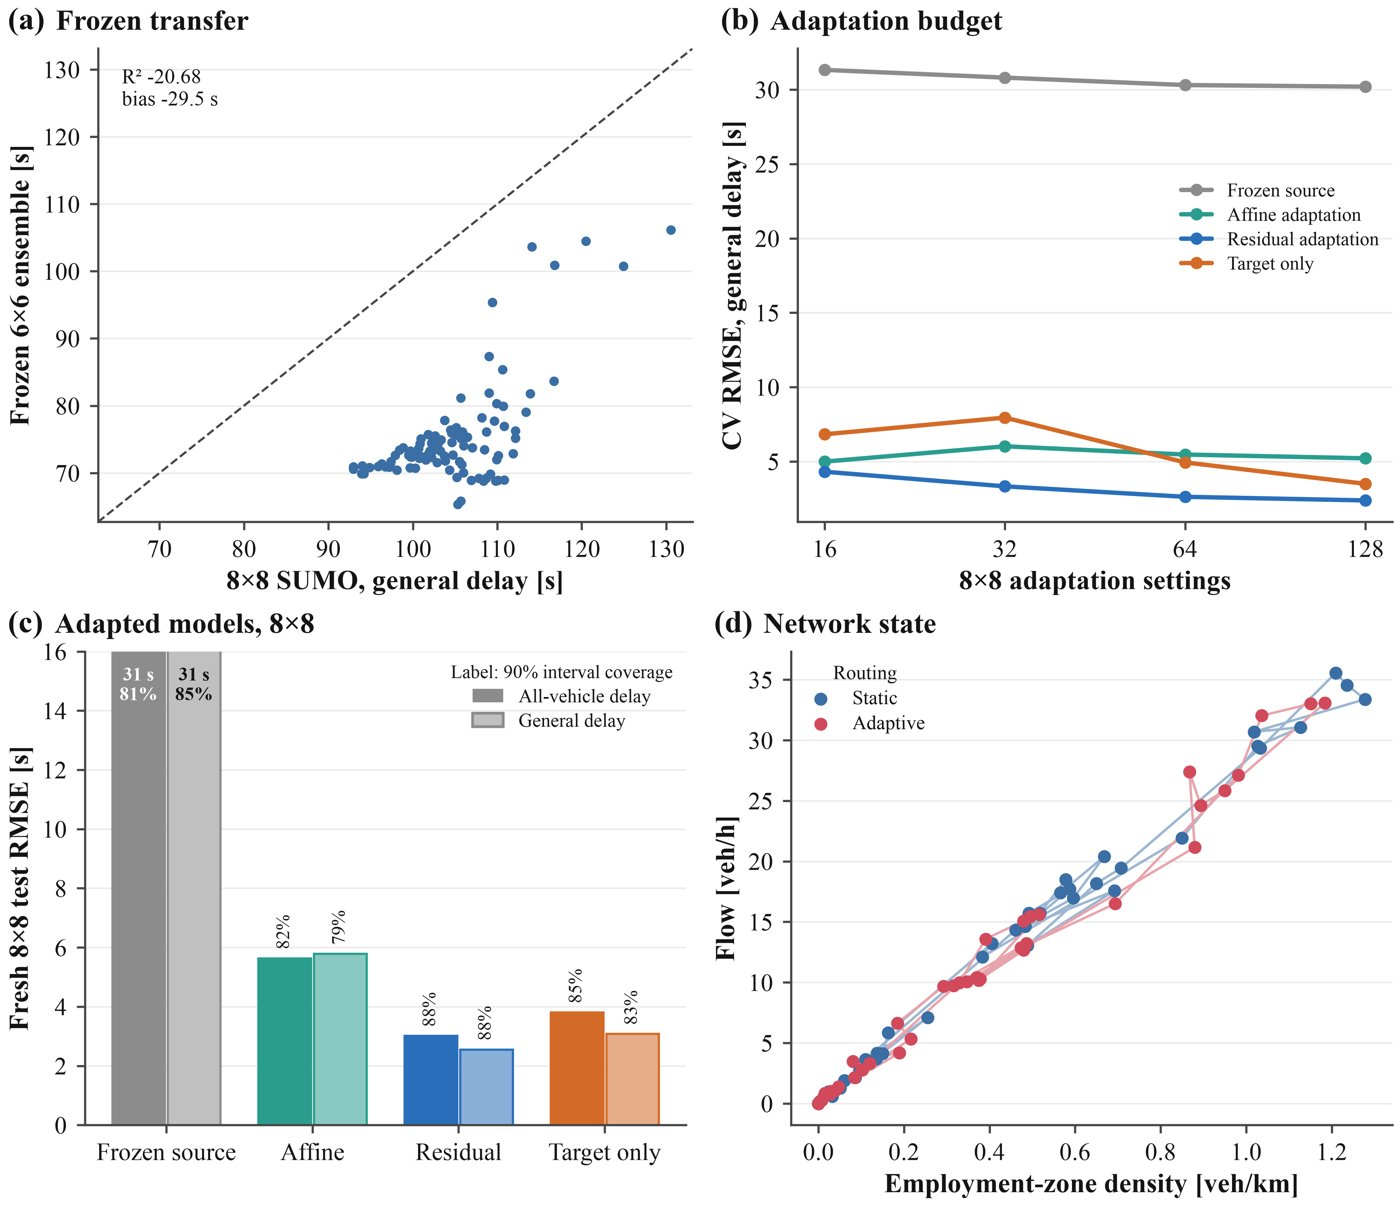

In [17]:
ensure('transfer')
display(T('adaptation_test_metrics'))
fig('Fig12_transfer_and_robustness')

## 14d. Runtime and simulation-quality audit
All runs, teleports, completion and surrogate speed-up.

In [18]:
ensure('runtime_quality')
display(T('simulation_audit_by_experiment')); print(json.dumps(json.load(open(study.root/'tables'/'runtime.json')), indent=1))

runtime_quality: complete (0.5 s)


,experiment,runs,unique_runs,mean_sec,total_min,runs_with_teleports,max_teleports,min_completion
0,adapt_calibration_runs_grid8,100,100,6.845,11.409,0,0.0,0.993
1,adapt_runs_grid8,128,128,6.488,13.842,0,0.0,0.990
2,adapt_test_runs_grid8,100,100,7.682,12.803,0,0.0,0.992
3,calibration,200,200,3.110,10.367,0,0.0,0.992
4,inverse_target_runs,100,100,3.759,6.265,0,0.0,0.990
5,inverse_validation_runs,200,200,3.803,12.677,0,0.0,0.990
6,mechanism_runs,1280,1280,3.546,75.658,0,0.0,0.995
7,recourse_runs,600,600,3.109,31.095,0,0.0,0.991
8,replication_runs,240,240,2.850,11.400,0,0.0,0.992
9,sobol_sumo_runs,5632,5632,3.408,319.887,0,0.0,0.987


{
 "total_simulations": 10216,
 "sumo_pipeline_mean_sec": 3.4711692561935266,
 "sumo_pipeline_median_sec": 3.2184523755022383,
 "total_cpu_hours": 9.850406978131408,
 "surrogate_sec_per_prediction": 6.574120800360106e-06,
 "speedup": 528005.0917231988,
 "workers": 8,
 "machine": "arm"
}


## 15. Manuscript figures
Figure-studio classic theme, 180 mm, PNG 600 dpi + PDF/SVG/TIFF.

figures: complete (35.7 s)


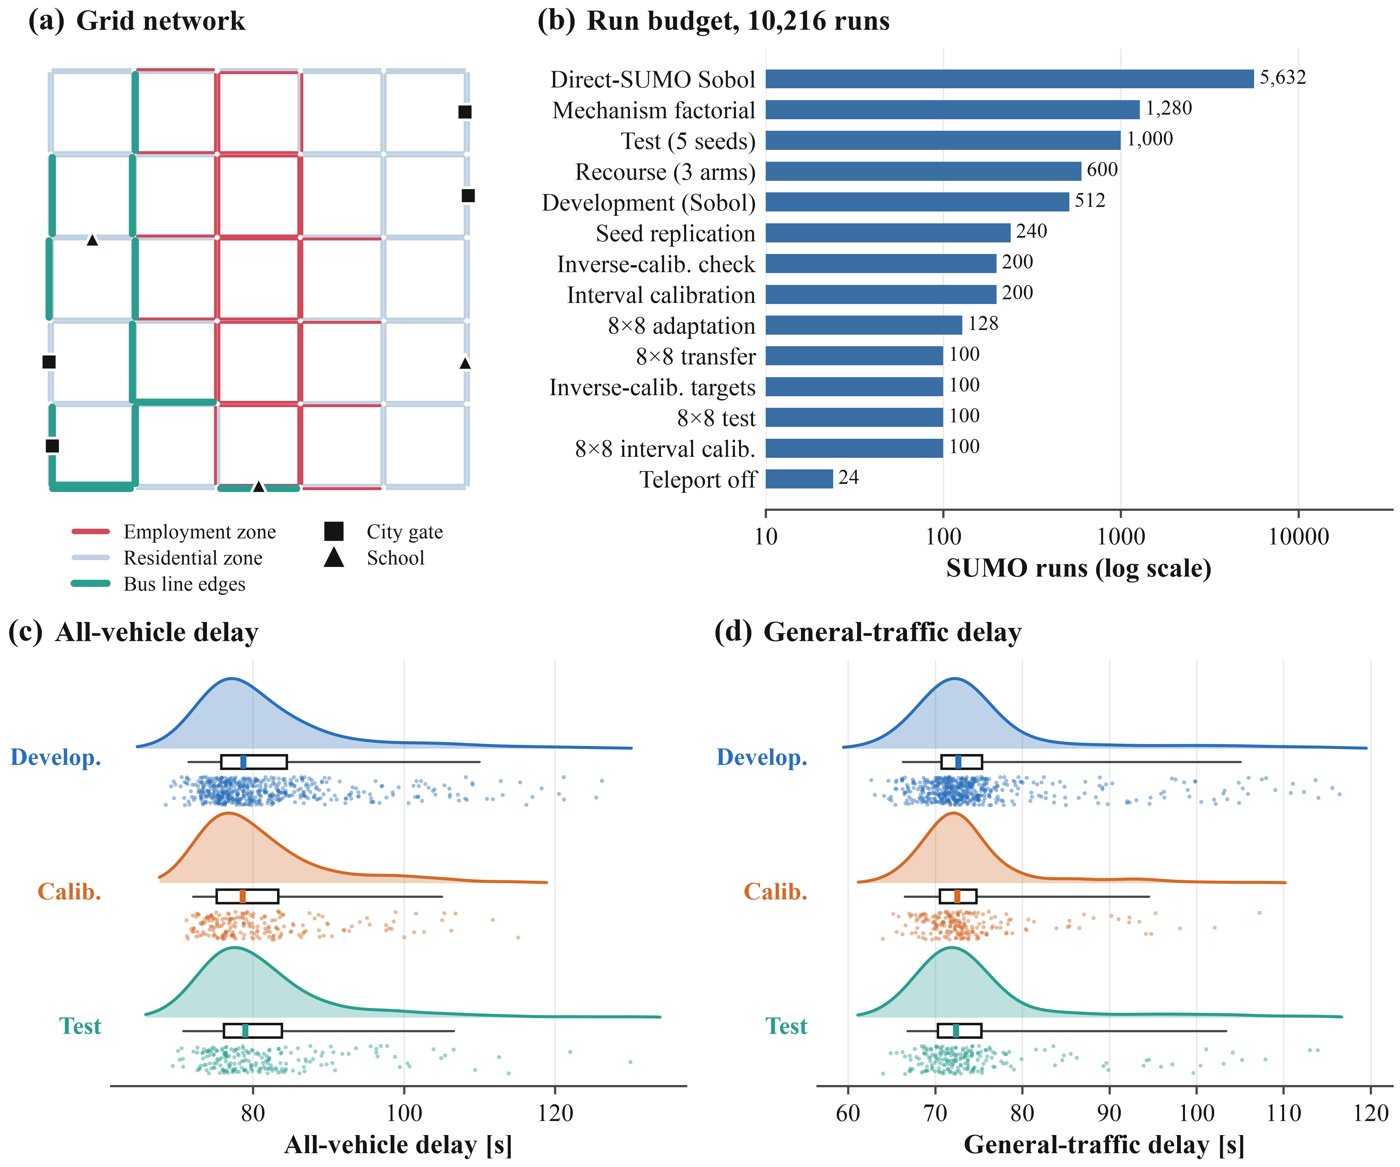

In [19]:
ensure('figures')
fig('Fig02_design_and_network')

## 16. Frozen export
Key numbers, LaTeX tables, SHA-256 manifest and results archive.

In [20]:
ensure('export')
print((study.root/'artifact_manifest.csv').read_text()[:800])

export: complete (2.9 s)
path,bytes,sha256
tables/adapt_calibration_runs_grid8.csv,71296,b36e2f99dd4f07db53bb15a72b67a21a0c41b58408fc7f6fb5aa508e592ccf15
tables/adapt_calibration_runs_grid8_failures.json,2,4f53cda18c2baa0c0354bb5f9a3ecbe5ed12ab4d8e11ba873c2f11161202b945
tables/adapt_runs_grid8.csv,87591,f7a059676b5f5acac879040aaa98dbbb5a785d7022416682a2d78d7f0d724226
tables/adapt_runs_grid8_failures.json,2,4f53cda18c2baa0c0354bb5f9a3ecbe5ed12ab4d8e11ba873c2f11161202b945
tables/adapt_test_runs_grid8.csv,69972,a23b8059efeeb29ca3c5e4f7665eab268b973b459cf72b1504822e41b1e47687
tables/adapt_test_runs_grid8_failures.json,2,4f53cda18c2baa0c0354bb5f9a3ecbe5ed12ab4d8e11ba873c2f11161202b945
tables/adaptation_intervals.csv,1294,718d2b84c2a09dcc7af4aeba7867f6136e00b7ba6de0358f739745ec9f3b5f70
tables/adaptation_learning.csv,636


## Boundaries that remain
* One synthetic grid family (6×6, with an 8×8 stress test); edge-order-based zones.
* activitygen emits vehicle trips only; bus outcomes are bus *vehicles*, not passengers.
* Simulator-internal effects are not real-world causal policy effects; no observed traffic data.